---

# _Análisis de turismo no residente en Argentina_

---
###### **Lo primero que vamos a hacer es importar las librerías que vamos a necesitar para poder correr correctamente el notebook.**

---

3.1. Carga y exploración inicial

---



In [28]:
import pandas as pd #para manipular los archivos
import matplotlib.pyplot as plt #para hacer gráficos
import seaborn as sb #para hacer gráficos
import numpy as np #para realizar operaciones matemáticas

In [29]:
#Vamos a cargar el dataset elegido a través de una url
url = 'https://raw.githubusercontent.com/SariChiba/El_Turismo_Esta_De_Vuelta/main/dataset/turistas-no-residentes-serie.csv'

#A continuación, le pedimos a pandas que lo lea y le asignamos un nombre para crear el dataframe
turismo = pd.read_csv(url)

#Ahora vamos a ver el dataframe que acabamos de crear
turismo

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,observaciones
0,2010-01-01,Aérea,Bolivia,4390,NaN
1,2010-01-01,Aérea,Brasil,72669,NaN
2,2010-01-01,Aérea,Chile,14726,NaN
3,2010-01-01,Aérea,Paraguay,4062,NaN
4,2010-01-01,Aérea,Uruguay,3512,NaN
...,...,...,...,...,...
5395,2026-08-01,Terrestre,Uruguay,27147,Dato provisorio
5396,2026-08-01,Terrestre,EE.UU. y Canadá,2268,Dato provisorio
5397,2026-08-01,Terrestre,Resto de América,8320,Dato provisorio
5398,2026-08-01,Terrestre,Europa,12908,Dato provisorio



---
##### En nuestro grupo, estuvimos de acuerdo que lo primero que queríamos hacer era modificar las fechas para que se lean de la forma en que estamos acostumbrados a hacerlo en Argentina. El objetivo es que el día quede primero y el año último.
##### ¿Por qué el cambio lo realizamos ahora y no más adelante? Más que nada por una cuestión de comodidad visual, preferible hacerlo antes de realizar algún otro cambio que dificulte la conversión más adelante.

In [30]:
#Convertimos la columna indice_tiempo a formato datetime para que pandas la reconozca de la forma correcta
turismo['indice_tiempo'] = pd.to_datetime(turismo['indice_tiempo'])

### ⚠️ Importante
A continuación, utilizamos la ayuda de la **IA** para cambiar del formato YYYY-MM-DD a DD-MM-YYYY.

> _Prompt utilizado: Cambiar el formato de las fechas de YYYY-MM-DD a DD-MM-YYYY_









In [31]:
# Cambiamos el formato de la columna indice_tiempo a DD-MM-YYYY
turismo['indice_tiempo'] = turismo['indice_tiempo'].dt.strftime('%d-%m-%Y')

# Ahora mostramos las primeras filas para verificar que se haya aplicado de forma correcta:
turismo.head(10)

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,observaciones
0,01-01-2010,Aérea,Bolivia,4390,NaN
1,01-01-2010,Aérea,Brasil,72669,NaN
2,01-01-2010,Aérea,Chile,14726,NaN
3,01-01-2010,Aérea,Paraguay,4062,NaN
4,01-01-2010,Aérea,Uruguay,3512,NaN
5,01-01-2010,Aérea,EE.UU. y Canadá,42783,NaN
6,01-01-2010,Aérea,Resto de América,36410,NaN
7,01-01-2010,Aérea,Europa,75995,NaN
8,01-01-2010,Aérea,Resto del mundo,15212,NaN
9,01-01-2010,Fluvial/Marítima,Bolivia,2304,NaN


In [32]:
#Mostramos las últimas filas usando .tail, también seleccionamos 10
turismo.tail(10)

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,observaciones
5390,01-08-2026,Fluvial/Marítima,Resto del mundo,1228,Dato provisorio
5391,01-08-2026,Terrestre,Bolivia,7336,Dato provisorio
5392,01-08-2026,Terrestre,Brasil,34488,Dato provisorio
5393,01-08-2026,Terrestre,Chile,10373,Dato provisorio
5394,01-08-2026,Terrestre,Paraguay,25351,Dato provisorio
5395,01-08-2026,Terrestre,Uruguay,27147,Dato provisorio
5396,01-08-2026,Terrestre,EE.UU. y Canadá,2268,Dato provisorio
5397,01-08-2026,Terrestre,Resto de América,8320,Dato provisorio
5398,01-08-2026,Terrestre,Europa,12908,Dato provisorio
5399,01-08-2026,Terrestre,Resto del mundo,2251,Dato provisorio


In [33]:
print("Dimensiones:", turismo.shape)
print("Columnas :", list(turismo.columns))
print("\nTipos de dato:")
print(turismo.dtypes)

print("MEMORIA  : %.2f MB" % (turismo.memory_usage(deep=True).sum() / 1024**2))

# Convertimos especificando explícitamente el formato original de la columna (día-mes-año) para evitar confusiones de fechas
fecha_min = pd.to_datetime(turismo["indice_tiempo"], format="%d-%m-%Y").min().date()
fecha_max = pd.to_datetime(turismo["indice_tiempo"], format="%d-%m-%Y").max().date()

print("\nPeríodo que cubre:", fecha_min, "→", fecha_max)

cantidad_visitantes_total = turismo['viajes_de_turistas_no_residentes'].sum()
print("\nCantidad total de visitantes no residentes:", cantidad_visitantes_total)

turismo.describe().round(2)

Dimensiones: (5400, 5)
Columnas : ['indice_tiempo', 'medio_de_transporte', 'pais_origen', 'viajes_de_turistas_no_residentes', 'observaciones']

Tipos de dato:
indice_tiempo                       object
medio_de_transporte                 object
pais_origen                         object
viajes_de_turistas_no_residentes     int64
observaciones                       object
dtype: object
MEMORIA  : 1.27 MB

Período que cubre: 2010-01-01 → 2026-08-01

Cantidad total de visitantes no residentes: 97999975


,viajes_de_turistas_no_residentes
count,5400.00
mean,18148.14
std,21317.76
min,0.00
25%,3325.00
50%,9184.00
75%,27894.75
max,213862.00


 3.2. Pregunta de investigación

---

 #####  *¿Cómo evolucionó el turismo no residente en Argentina en los últimos años?*





In [34]:
# Obtenemos la cantidad de Visitantes no residentes por año

# Convertir la fecha a formato de fecha correctamente usando pd.to_datetime
turismo['indice_tiempo'] = pd.to_datetime(turismo['indice_tiempo'], format='%d-%m-%Y')

# Crear la columna año
turismo['anio'] = turismo['indice_tiempo'].dt.year

# Sumar los viajes de todos los meses, países y transportes de cada año
visitas_por_anio = (
    turismo.groupby('anio')['viajes_de_turistas_no_residentes']
      .sum()
      .reset_index()
)

# Mostrar los resultados
visitas_por_anio.columns = ['Año', 'Cantidad de visitas']
display(visitas_por_anio)

,Año,Cantidad de visitas
0,2010,6738593
1,2011,6674029
2,2012,6461769
3,2013,6510286
4,2014,7165219
5,2015,6815623
6,2016,6668207
7,2017,6711248
8,2018,6941767
9,2019,7398973


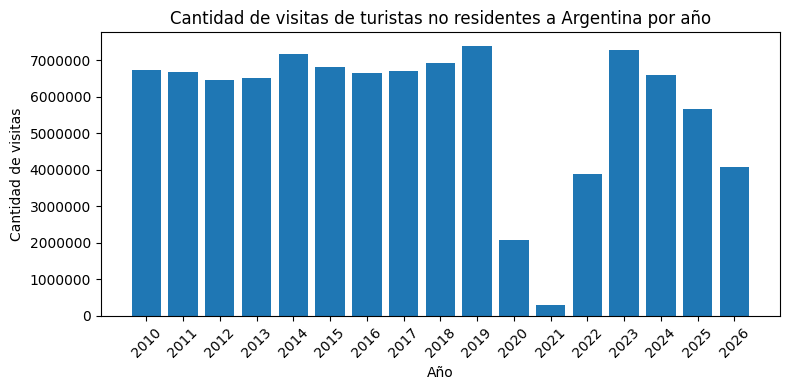

In [35]:
# GRÁFICAMENTE:

fig, ax = plt.subplots(figsize=(8, 4))
plt.bar(
    visitas_por_anio['Año'],
    visitas_por_anio['Cantidad de visitas'],
    width=0.8  # Barras más angostas y más espacio entre ellas
)

plt.title('Cantidad de visitas de turistas no residentes a Argentina por año')
plt.xlabel('Año')
plt.ylabel('Cantidad de visitas')
plt.xticks(visitas_por_anio['Año'], rotation=45)

plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.)
plt.tight_layout()
plt.show()

In [36]:
# Año base de la comparación
base_2019 = visitas_por_anio.loc[visitas_por_anio['Año'] == 2019, 'Cantidad de visitas'].iloc[0]

# Variación porcentual de cada año respecto de 2019
visitas_por_anio['Variación vs 2019 (%)'] = (
    (visitas_por_anio['Cantidad de visitas'] - base_2019) / base_2019 * 100
    ).round(1)

display(visitas_por_anio[visitas_por_anio['Año'] >= 2019])

,Año,Cantidad de visitas,Variación vs 2019 (%)
9,2019,7398973,0.0
10,2020,2089504,-71.8
11,2021,297421,-96.0
12,2022,3889701,-47.4
13,2023,7285646,-1.5
14,2024,6603828,-10.7
15,2025,5680763,-23.2
16,2026,4067398,-45.0


In [37]:
# Comparamos 2026 (ene-ago) contra el mismo período de 2019
turismo['mes'] = turismo['indice_tiempo'].dt.month
ene_ago = turismo[turismo['mes'] <= 8].groupby('anio')['viajes_de_turistas_no_residentes'].sum()

var_2026 = (ene_ago[2026] - ene_ago[2019]) / ene_ago[2019] * 100
print(f"Ene-ago 2026 vs ene-ago 2019: {var_2026:.1f}%")

Ene-ago 2026 vs ene-ago 2019: -15.9%


#¿Cómo interpretar los resultados?
Al observar el gráfico podemos concluir lo siguiente:

Año 2019 (7,40 millones de viajes) es el máximo de la serie y la referencia para comparar.
- 2020 y 2021: Una fuerte caída en los registros, del 71,8% y 96,0% respecto de 2019, por el cierre de fronteras durante la pandemia de COVID-19.
- 2022: la recuperación empezó, pero seguía 47,4% por debajo de 2019.
- 2023: Una recuperación importante se llegó prácticamente al nivel previo (-1,5%).
- 2024 y 2025: el turismo volvió a caer, 10,7% y 23,2% por debajo de 2019. Es decir, la recuperación de 2023 no se sostuvo.
- 2026: los datos llegan solo hasta agosto. Comparado contra el mismo período de 2019, el nivel es de aproximadamente 16% menos.